# Cómo decide un buscador qué mostrar primero

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | Un buscador ordena una colección entera, y «mejor» depende de juicios de una persona. |
| **Producto** | Funciones de ranking y de métricas escritas por vos, la evaluación de una consulta propia y una decisión de uso. |
| **Recursos** | Word2Vec (unos 2 GB) y un modelo de oraciones (unos 470 MB). Con poca memoria, `LIMITE_DE_PALABRAS = 200000`. |

Hasta acá comparamos pares. Un buscador recibe una frase y ordena **toda** la colección de más a menos parecido, para que lo útil aparezca arriba. Lo mismo ocurre en los sistemas que consultan documentos antes de responder (recuperación para modelos de lenguaje): si el fragmento correcto no está entre los primeros, la respuesta sale sin él.

**¿Cómo sabemos qué método ordena mejor, y cuánto podemos creerle a esa respuesta?**

> **Cómo se trabaja.** Explorás cada tema con el código ya escrito y las notas **Para mirar**. Al final de cada bloque, un **microlaboratorio** te dice qué líneas completar y con qué; la celda siguiente comprueba.

In [1]:
import sys
import hashlib
import importlib.metadata
from typing import Callable

import numpy as np
import pandas as pd
from IPython.display import display

from gensim.models import KeyedVectors
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer

import utils

# La semilla fija el remuestreo de la seccion 4 y el PCA de la seccion 6.
SEMILLA = 42

# None carga todo Word2Vec. Con poca memoria, proba con 200000.
LIMITE_DE_PALABRAS = None

pd.set_option("display.max_colwidth", 90)

print("Python:", sys.version.split()[0])
paquetes = ["gensim", "sentence-transformers", "scikit-learn", "numpy",
            "pandas", "matplotlib"]
for paquete in paquetes:
    print(f"{paquete}: {importlib.metadata.version(paquete)}")
print("Semilla:", SEMILLA, "| limite de palabras:", LIMITE_DE_PALABRAS)

W1019 15:07:23.882000 13060 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Python: 3.12.13
gensim: 4.4.0
sentence-transformers: 6.1.0
scikit-learn: 1.9.1
numpy: 2.5.4
pandas: 3.0.6
matplotlib: 3.11.2
Semilla: 42 | limite de palabras: None


## 1. La colección, las consultas y los juicios

Evaluar un buscador necesita tres cosas: una colección, **consultas** y **juicios de relevancia** (una persona decide cuán pertinente es cada fragmento para cada consulta: 2 relevante, 1 parcial, 0 no relevante).

| Campo | Contenido |
|---|---|
| Colección | `datos/fragmentos.csv`: 137 fragmentos de 34 textos (Karen Palacio, ciudadseva.com). Detalle en `datos/FUENTE.md` |
| Consultas | `datos/consultas.csv`: 10, escritas por quien armó la unidad, con un criterio de relevancia cada una |
| Juicios | `datos/juicios_de_relevancia.csv`: 83 (relevante = 2, parcial = 1). **Lo que no figura vale 0** |
| Quién juzgó | una sola persona, leyendo los 137 fragmentos. Sin segunda evaluación |
| Cuándo | **antes** de calcular cualquier ranking (el hash de abajo deja constancia) |

Con este tamaño no se pueden establecer diferencias generales entre métodos. Sí se puede ver cómo se decide con evidencia pequeña y qué la debilita.

In [2]:
fragmentos = utils.cargar_fragmentos()
consultas = utils.cargar_consultas()
juicios = utils.cargar_juicios()

lista_de_ids = list(fragmentos["id"])
textos_de_la_coleccion = list(fragmentos["texto"])
print(f"{len(fragmentos)} fragmentos | {len(consultas)} consultas | "
      f"{len(juicios)} juicios")
display(consultas[["id", "consulta", "tipo"]])

# El hash de un archivo cambia si se modifica una sola letra: sirve para
# saber que usamos los juicios que se fijaron antes de evaluar.
with open("datos/juicios_de_relevancia.csv", "rb") as archivo:
    hash_de_los_juicios = hashlib.sha256(archivo.read()).hexdigest()
discutibles = int((juicios["discutible"] == "sí").sum())
print("SHA-256 de los juicios (16 primeros):", hash_de_los_juicios[:16])
print(f"Juicios marcados como discutibles: {discutibles} de {len(juicios)}")

assert set(juicios["id_fragmento"]) <= set(lista_de_ids), "Fragmento ajeno."
assert set(juicios["id_consulta"]) <= set(consultas["id"]), "Consulta ajena."
assert not juicios.duplicated(["id_consulta", "id_fragmento"]).any()
assert not fragmentos["texto"].str.contains("relevan", case=False).any()

137 fragmentos | 10 consultas | 83 juicios


,id,consulta,tipo
0,C01,Un animal desea ser otra cosa distinta de lo que es,parafraseada
1,C02,Alguien muere antes de la boda o poco después del casamiento,léxica parcial
2,C03,Alguien intenta quitarse la vida,parafraseada
3,C04,Quién prepara la comida,trampa léxica
4,C05,Quien vuelve de un viaje largo y ya no encuentra su casa como la dejó,parafraseada
5,C06,La lectura de libros de aventuras confunde a un hombre sobre lo real,parafraseada
6,C07,Un gobernante o un rey ejerce su poder sobre otros,léxica genérica
7,C08,"Instrucciones detalladas para una acción cotidiana, contadas con humor",género
8,C09,El miedo de estar solo en la selva de noche,léxica
9,C10,La Muerte se presenta como un personaje que habla,trampa léxica


SHA-256 de los juicios (16 primeros): 9e217d46f9337000
Juicios marcados como discutibles: 39 de 83


> **Para mirar.**
>
> - las consultas son de tipos distintos: algunas comparten palabras con lo relevante (`léxica`), otras lo describen con otras palabras (`parafraseada`), una pide una forma (`género`) y dos son `trampa léxica`. Es deliberado: queremos ver dónde falla cada método.
> - **39 de los 83 juicios** están marcados como discutibles. Cualquier diferencia chica entre métodos puede deberse a cómo se decidió un juicio dudoso.

**Juzgá antes de ver.** Para sentir cuánto de «relevante» es una decisión, asigná mentalmente 0, 1 o 2 a estos fragmentos para la consulta **C02** (*Alguien muere antes de la boda o poco después del casamiento*) y recién después corré la celda que muestra los nuestros.

In [3]:
fragmentos_para_calibrar = [
    "una-plaza-en-el-cielo-01", "una-plaza-en-el-cielo-02", "la-foto-01",
    "la-foto-02", "danza-macabra-iii-01", "la-muerte-anderson-01",
]
textos_por_id = fragmentos.set_index("id")["texto"].to_dict()
for identificador in fragmentos_para_calibrar:
    print(f"[{identificador}]", textos_por_id[identificador][:200], "...")

[una-plaza-en-el-cielo-01] Etelvina y Luis van a casarse. En vísperas de la boda, Luis muere. Etelvina se resigna porque confía en que volverán a encontrarse en el Cielo. Pasan los años y ella espera, espera… Espera que Dios la ...
[una-plaza-en-el-cielo-02] De pronto -en el crepúsculo tocan las campanas del ángelus- ve entre los árboles a Luis, que se acerca a paso lento. (No es Luis: es un joven de la vecindad muy parecido al recuerdo que Etelvina conse ...
[la-foto-01] Jaime y Paula se casaron. Ya durante la luna de miel fue evidente que Paula se moría. Apenas unos pocos meses de vida le pronosticó el médico. Jaime, para conservar ese bello rostro, le pidió que se d ...
[la-foto-02] ¡Clic! Poco después, la muerte. Entonces Jaime hizo ampliar la foto -la cara de Paula era bella como una flor-, le puso vidrio, marco y la colocó en la mesita de noche. Una mañana, al despertarse, vio ...
[danza-macabra-iii-01] Cuando Pablo tenía diez años bajó al sótano y vio a su padre ahorcado del tec

In [4]:
juicios_de_c02 = juicios[juicios["id_consulta"] == "C02"]
juicios_de_c02 = juicios_de_c02.set_index("id_fragmento")
for identificador in fragmentos_para_calibrar:
    if identificador in juicios_de_c02.index:
        fila = juicios_de_c02.loc[identificador]
        print(f"{identificador}: {fila['relevancia']} "
              f"(discutible: {fila['discutible']}) {fila['justificacion']}")
    else:
        print(f"{identificador}: 0 (sin juicio registrado)")

una-plaza-en-el-cielo-01: 2 (discutible: no) Luis muere en vísperas de la boda.
una-plaza-en-el-cielo-02: 1 (discutible: sí) Continúa la espera de Etelvina.
la-foto-01: 2 (discutible: no) Paula se muere durante la luna de miel.
la-foto-02: 1 (discutible: sí) Consecuencia de la muerte de Paula.
danza-macabra-iii-01: 1 (discutible: sí) Noche de bodas, pero no muere nadie en el fragmento.
la-muerte-anderson-01: 0 (sin juicio registrado)


> **Para mirar.** *danza-macabra-iii-01* pasa en una noche de bodas pero no muere nadie en el fragmento: ¿parcial o no relevante? Los dos juicios son defendibles y cada uno cambia las métricas que siguen.

## 2. Tres maneras de ordenar la misma colección

Cada método convierte la colección en vectores, convierte la consulta del mismo modo y ordena los fragmentos por coseno. Regla: **la colección se vectoriza una sola vez**; si el vectorizador TF-IDF se ajustara con cada consulta, cambiaría el peso de todas las palabras y dos consultas no serían comparables.

| Método | Preprocesamiento | Motivo |
|---|---|---|
| TF-IDF | sin palabras vacías | es lo que usamos en el cuaderno 01 |
| Promedio de vectores | sin palabras vacías, minúsculas | mismo preprocesamiento, para comparar |
| Embedding de oración | ninguno; trunca a 128 tokens | es el protocolo del modelo (cuaderno 04) |

In [5]:
with open("datos/stopwords_es.txt", encoding="utf-8") as archivo:
    palabras_vacias = archivo.read().split()

# fit_transform aprende el vocabulario y los pesos IDF, una sola vez.
vectorizador_tfidf = TfidfVectorizer(
    token_pattern=utils.PATRON_DE_PALABRA, stop_words=palabras_vacias
)
matriz_tfidf = vectorizador_tfidf.fit_transform(
    raw_documents=textos_de_la_coleccion
)
print("TF-IDF de la coleccion:", matriz_tfidf.shape)


def puntajes_tfidf(consulta: str) -> np.ndarray:
    """Calcula el coseno entre la consulta y cada fragmento, con TF-IDF.

    La consulta se transforma con el vocabulario de la coleccion
    (transform), sin volver a ajustar nada.

    Args:
        consulta: El texto de la consulta.

    Returns:
        Un puntaje por fragmento.
    """
    vector = vectorizador_tfidf.transform(raw_documents=[consulta])
    return utils.cosenos_contra_todas_las_filas(
        matriz_tfidf, vector.toarray()[0]
    )

TF-IDF de la coleccion: (137, 2641)


Segundo, el promedio de vectores de palabras (Word2Vec, SBW 2016): el mecanismo del cuaderno 04 aplicado a 137 textos.

In [6]:
vectores_word2vec = utils.cargar_vectores_word2vec(limite=LIMITE_DE_PALABRAS)
print(f"Word2Vec: {len(vectores_word2vec.key_to_index):,} palabras")


def promedio_del_texto(texto: str) -> np.ndarray:
    """Promedia los vectores de las palabras con contenido de un texto.

    Args:
        texto: El texto a promediar.

    Returns:
        Un vector de 300 numeros, o None si ninguna palabra tiene vector.
    """
    con_contenido = []
    for palabra in utils.separar_palabras(texto):
        if palabra not in palabras_vacias:
            con_contenido.append(palabra)
    promedio, sin_cobertura = utils.promedio_de_vectores(
        con_contenido, vectores_word2vec
    )
    return promedio


promedios = []
sin_vector = 0
for texto in textos_de_la_coleccion:
    promedio = promedio_del_texto(texto)
    if promedio is None:
        sin_vector += 1
        promedio = np.zeros(vectores_word2vec.vector_size)
    promedios.append(promedio)
matriz_promedios = np.array(promedios)
print("Promedios:", matriz_promedios.shape,
      "| fragmentos sin ningun vector:", sin_vector)


def puntajes_promedio(consulta: str) -> np.ndarray:
    """Calcula el coseno entre el promedio de la consulta y los fragmentos.

    Args:
        consulta: El texto de la consulta.

    Returns:
        Un puntaje por fragmento (nan si la consulta no tiene vectores).
    """
    de_la_consulta = promedio_del_texto(consulta)
    if de_la_consulta is None:
        return np.full(len(lista_de_ids), np.nan)
    return utils.cosenos_contra_todas_las_filas(
        matriz_promedios, de_la_consulta
    )

Word2Vec: 1,692,025 palabras
Promedios: (137, 300) | fragmentos sin ningun vector: 0


Tercero, el modelo de oraciones del cuaderno 04. Lee solo los primeros 128 tokens de cada fragmento.

In [7]:
modelo_de_oraciones = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)
matriz_de_oraciones = modelo_de_oraciones.encode(
    textos_de_la_coleccion, batch_size=32, show_progress_bar=False
)
print("Embeddings:", matriz_de_oraciones.shape, "| longitud maxima:",
      modelo_de_oraciones.max_seq_length, "tokens")


def puntajes_oracion(consulta: str) -> np.ndarray:
    """Calcula el coseno entre el embedding de la consulta y los fragmentos.

    Args:
        consulta: El texto de la consulta.

    Returns:
        Un puntaje por fragmento.
    """
    vector = modelo_de_oraciones.encode([consulta], show_progress_bar=False)
    return utils.cosenos_contra_todas_las_filas(
        matriz_de_oraciones, vector[0]
    )


METODOS = {
    "TF-IDF": puntajes_tfidf,
    "promedio de vectores": puntajes_promedio,
    "embedding de oracion": puntajes_oracion,
}

# Control: cada metodo da un puntaje por fragmento, dentro de [-1, 1] o nan.
una_consulta = consultas.loc[0, "consulta"]
for nombre, funcion in METODOS.items():
    puntajes = funcion(una_consulta)
    assert len(puntajes) == len(fragmentos), f"{nombre}: falta un puntaje."
    assert np.nanmin(puntajes) >= -1.0001, f"{nombre}: coseno fuera de rango."
    assert np.nanmax(puntajes) <= 1.0001, f"{nombre}: coseno fuera de rango."
    print(f"{nombre}: minimo {np.nanmin(puntajes):.2f} | "
          f"maximo {np.nanmax(puntajes):.2f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 21352.43it/s]

Embeddings: (137, 384) | longitud maxima: 128 tokens
TF-IDF: minimo 0.00 | maximo 0.11
promedio de vectores: minimo 0.47 | maximo 0.77
embedding de oracion: minimo -0.03 | maximo 0.56


> **Para mirar.** los rangos son muy distintos: TF-IDF no pasa de 0,11, el promedio nunca baja de 0,47 y el embedding va de −0,03 a 0,56. Los puntajes de métodos distintos **no se comparan entre sí**: lo que se evalúa es el **ranking**, no el número.

## 3. Mirar los rankings, no solo los números

Antes de resumir con una métrica, miramos los tres primeros de cada método, con su relevancia según los juicios. Empezamos por **C01**: *Un animal desea ser otra cosa distinta de lo que es*, una consulta parafraseada.

In [8]:
def mostrar_los_primeros(id_consulta: str, cantidad: int = 3) -> None:
    """Muestra los primeros resultados de cada metodo para una consulta.

    Args:
        id_consulta: Id de la consulta, por ejemplo "C01".
        cantidad: Cuantos resultados mostrar por metodo.
    """
    fila = consultas.loc[consultas["id"] == id_consulta, "consulta"]
    texto_de_la_consulta = fila.iloc[0]
    relevancias = utils.relevancias_de_una_consulta(
        lista_de_ids, juicios, id_consulta
    )
    print(f"{id_consulta}: {texto_de_la_consulta}")
    for nombre, funcion in METODOS.items():
        puntajes = funcion(texto_de_la_consulta)
        orden = utils.ordenar_por_puntaje(puntajes)
        print(f"  {nombre}")
        for lugar in orden[:cantidad]:
            print(f"    {puntajes[lugar]:.2f} | relevancia "
                  f"{relevancias[lugar]} | {lista_de_ids[lugar]}")
    print()


mostrar_los_primeros("C01")

C01: Un animal desea ser otra cosa distinta de lo que es
  TF-IDF
    0.11 | relevancia 0 | el-rinoceronte-2-03
    0.11 | relevancia 0 | suicidio-2-01
    0.10 | relevancia 2 | la-mosca-que-sonaba-que-era-un-aguila-02
  promedio de vectores
    0.77 | relevancia 0 | suicidio-2-01
    0.76 | relevancia 0 | un-problema-02
    0.76 | relevancia 0 | un-problema-04
  embedding de oracion
    0.56 | relevancia 1 | el-rinoceronte-2-05
    0.54 | relevancia 0 | la-jirafa-03
    0.50 | relevancia 0 | el-rinoceronte-2-02



> **Para mirar.** solo el embedding pone primero un fragmento con alguna relevancia (parcial). TF-IDF pone el relevante tercero y el promedio no lo incluye. La consulta describe la situación en abstracto, sin nombrar a ningún animal.

Ahora **C04**, *Quién prepara la comida*, una trampa léxica, y **C10**, *La Muerte se presenta como un personaje que habla*.

In [9]:
mostrar_los_primeros("C04")
mostrar_los_primeros("C10")

C04: Quién prepara la comida
  TF-IDF
    0.18 | relevancia 2 | tres-cocineros-y-un-huevo-frito-02
    0.17 | relevancia 0 | el-suicida-02
    0.13 | relevancia 0 | la-melancolia-del-viajero-01
  promedio de vectores
    0.74 | relevancia 1 | almuerzos-01
    0.74 | relevancia 2 | tres-cocineros-y-un-huevo-frito-02
    0.72 | relevancia 2 | tres-cocineros-y-un-huevo-frito-03
  embedding de oracion
    0.54 | relevancia 1 | el-cocinero-02
    0.52 | relevancia 1 | el-cocinero-05
    0.48 | relevancia 2 | la-cocinera-01

C10: La Muerte se presenta como un personaje que habla
  TF-IDF
    0.16 | relevancia 0 | la-cocinera-05
    0.09 | relevancia 0 | la-foto-02
    0.09 | relevancia 2 | la-muerte-anderson-04
  promedio de vectores
    0.75 | relevancia 0 | un-problema-01
    0.74 | relevancia 0 | un-problema-02
    0.73 | relevancia 0 | almuerzos-02
  embedding de oracion
    0.56 | relevancia 0 | un-problema-06
    0.52 | relevancia 0 | suicidio-2-01
    0.51 | relevancia 0 | literatura-

> **Para mirar.**
>
> - **C04:** los tres ponen primero algo relevante (TF-IDF uno total; los otros, parcial). Cambia la calidad del primer resultado, no que acierten.
> - **C10:** ninguno acierta el primer lugar. TF-IDF pone un fragmento que comparte la palabra *personaje*; los otros, fragmentos de muerte, suicidio o locura, pero no de la Muerte hablando. La consulta pide una **estructura** que ninguna representación captura.

**Cuando la consulta es un fragmento de la colección** (buscar «fragmentos parecidos a este»), el propio fragmento aparece primero con coseno 1. Hay que sacarlo **por su posición**, no suponiendo que es el primero (si hubiera un duplicado exacto, sacaríamos el duplicado).

In [10]:
identificador = "el-suicida-01"
lugar_de_la_consulta = lista_de_ids.index(identificador)
puntajes = utils.cosenos_contra_todas_las_filas(
    matriz_de_oraciones, matriz_de_oraciones[lugar_de_la_consulta]
)
sin_excluir = utils.ordenar_por_puntaje(puntajes)
excluyendo = utils.ordenar_por_puntaje(
    puntajes, indice_a_excluir=lugar_de_la_consulta
)
print("Sin excluir, el primero es:", lista_de_ids[sin_excluir[0]],
      "con coseno", round(puntajes[sin_excluir[0]], 2))
print("Excluyendo la consulta:")
for lugar in excluyendo[:3]:
    print(f"  {puntajes[lugar]:.2f} | {lista_de_ids[lugar]}")

Sin excluir, el primero es: el-suicida-01 con coseno 1.0
Excluyendo la consulta:
  0.62 | el-suicida-03
  0.56 | el-suicida-02
  0.54 | noctilucas-03


> **Para mirar.** si olvidás excluir la consulta, la precisión sube porque contás como hallazgo una respuesta que no lo es. Un error silencioso común. Acá no importa: las diez consultas de la evaluación son frases externas.

### Microlaboratorio 1 — Armar un ranking

**Tarea.** Escribir una función que, dada una consulta y un método, devuelva los ids de los primeros resultados.  
**Producto.** `ranking_de_una_consulta`, comprobada, y el ranking de una consulta propia con los tres métodos.  
**Antes de empezar.** Secciones 2 y 3.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `puntajes` | un puntaje por fragmento | llamar a `funcion_de_puntajes` con la `consulta` |
| (2) `orden` | las posiciones ordenadas de mayor a menor puntaje | `utils.ordenar_por_puntaje` con los `puntajes` |
| (3) `ids` | los ids de los primeros `cantidad` resultados | un bucle sobre `orden[:cantidad]` que agrega `lista_de_ids[lugar]` a la lista |
| Paso 2 `mi_consulta` | una frase tuya | algo que buscarías en estos cuentos |

**Comprobación.** para C01, el embedding debe poner primero `el-rinoceronte-2-05` y TF-IDF debe tener `la-mosca-que-sonaba-que-era-un-aguila-02` en el tercer lugar.

> **Ayuda 1.** Las tres líneas repiten lo que hace `mostrar_los_primeros`, sin imprimir.  
> **Ayuda 2.** `orden` es un arreglo de posiciones; `lista_de_ids[posicion]` da el id de esa posición.

In [11]:
def ranking_de_una_consulta(
    consulta: str, funcion_de_puntajes: Callable, cantidad: int = 3
) -> list:
    """Devuelve los ids de los primeros resultados para una consulta.

    Args:
        consulta: El texto de la consulta.
        funcion_de_puntajes: Una de las funciones de METODOS.
        cantidad: Cuantos resultados devolver.

    Returns:
        Lista de ids de fragmentos, del mejor al peor.
    """
    puntajes = []  # COMPLETAR (1)
    orden = []  # COMPLETAR (2)
    ids = []
    for lugar in orden[:cantidad]:
        pass  # COMPLETAR (3)
    return ids


texto_c01 = consultas.loc[0, "consulta"]
con_embedding = ranking_de_una_consulta(texto_c01, puntajes_oracion)
con_tfidf = ranking_de_una_consulta(texto_c01, puntajes_tfidf)
utils.comprobar(
    con_embedding[:1] == ["el-rinoceronte-2-05"]
    and con_tfidf[2:3] == ["la-mosca-que-sonaba-que-era-un-aguila-02"],
    "revisa (1), (2) y (3): mira los primeros de C01 en la seccion 3",
)

# PASO 2: escribi tu consulta.
mi_consulta = "Alguien espera algo que no llega"
for nombre, funcion in METODOS.items():
    print(nombre, "->", ranking_de_una_consulta(mi_consulta, funcion))

Todavia falta. Pista: revisa (1), (2) y (3): mira los primeros de C01 en la seccion 3
TF-IDF -> []
promedio de vectores -> []
embedding de oracion -> []


## 4. Medir con una métrica explícita

- **Precisión@3:** de los tres primeros resultados, qué proporción es relevante.
- **Rango recíproco (RR):** 1 dividido la posición del primer relevante (1 si es el primero, 0,5 si es el segundo, 0 si no aparece). Su promedio entre consultas es el MRR.

Calculamos las dos aceptando relevantes y parciales (relevancia ≥ 1) o solo los totales (= 2), porque contar los parciales como aciertos **es parte del criterio de relevancia** y queremos ver cuánto pesa.

,P@3 (>=1),P@3 (=2),RR (>=1),RR (=2)
TF-IDF,0.40,0.37,0.65,0.63
promedio de vectores,0.43,0.20,0.61,0.43
embedding de oracion,0.43,0.30,0.74,0.58


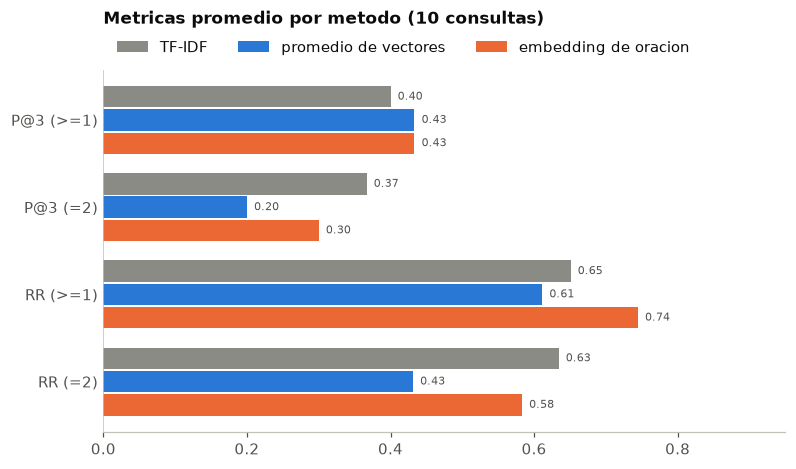

In [12]:
def evaluar_un_metodo(funcion_de_puntajes: Callable) -> pd.DataFrame:
    """Calcula las metricas de un metodo para cada consulta.

    Args:
        funcion_de_puntajes: Una de las funciones de METODOS.

    Returns:
        Tabla con una fila por consulta y cuatro metricas.
    """
    filas = []
    for id_consulta in consultas["id"]:
        fila = consultas.loc[consultas["id"] == id_consulta, "consulta"]
        relevancias = utils.relevancias_de_una_consulta(
            lista_de_ids, juicios, id_consulta
        )
        puntajes = funcion_de_puntajes(fila.iloc[0])
        orden = utils.ordenar_por_puntaje(puntajes)
        ordenadas = relevancias[orden]
        filas.append({
            "consulta": id_consulta,
            "P@3 (>=1)": utils.precision_en_k(ordenadas, k=3, umbral=1),
            "P@3 (=2)": utils.precision_en_k(ordenadas, k=3, umbral=2),
            "RR (>=1)": utils.rango_reciproco(ordenadas, umbral=1),
            "RR (=2)": utils.rango_reciproco(ordenadas, umbral=2),
        })
    return pd.DataFrame(filas).set_index("consulta")


resultados_por_metodo = {}
promedios_por_metodo = {}
for nombre, funcion in METODOS.items():
    resultados_por_metodo[nombre] = evaluar_un_metodo(funcion)
    promedios_por_metodo[nombre] = resultados_por_metodo[nombre].mean()
resumen = pd.DataFrame(promedios_por_metodo).T
display(resumen.round(2))

series = {}
for nombre in resumen.index:
    series[nombre] = list(resumen.loc[nombre])
utils.dibujar_barras_agrupadas(
    list(resumen.columns), series,
    "Metricas promedio por metodo (10 consultas)", maximo=0.95,
)

> **Para mirar.** con P@3 (≥1) los tres quedan entre 0,40 y 0,43. Y el orden **cambia** según la versión: con RR (≥1) gana el embedding (0,74); con RR (=2) gana TF-IDF (0,63). La diferencia entre métodos es del tamaño de la diferencia entre dos criterios razonables de relevancia: no se puede decir cuál es «mejor» sin decir para qué criterio.

In [13]:
rr = {}
for nombre, tabla in resultados_por_metodo.items():
    rr[nombre] = tabla["RR (>=1)"]
display(pd.DataFrame(rr).round(2))

,TF-IDF,promedio de vectores,embedding de oracion
consulta,,,
C01,0.33,0.25,1.00
C02,1.00,0.50,1.00
C03,1.00,0.25,1.00
C04,1.00,1.00,1.00
C05,0.33,1.00,1.00
C06,0.50,1.00,0.25
C07,1.00,1.00,1.00
C08,0.01,0.07,0.05
C09,1.00,1.00,1.00


> **Para mirar.** por consulta, **ningún método gana siempre**: el embedding acierta primero en C01, C02, C03, C04, C05, C07 y C09, pero cae a 0,25 en C06. En C08 y C10 los tres fallan.

**¿Cuánto cambia con otras diez consultas?** Remuestreamos: armamos 2.000 grupos de 10 consultas sacadas con reposición de las 10 que tenemos y calculamos en cada uno la diferencia de MRR (≥1) entre el embedding y TF-IDF. El rango que cubre la mayoría da una idea de la **incertidumbre**, no de la verdad.

In [14]:
generador = np.random.default_rng(SEMILLA)
rr_embedding = rr["embedding de oracion"].values
rr_tfidf = rr["TF-IDF"].values

diferencias = []
for repeticion in range(2000):
    elegidas = generador.integers(0, len(rr_tfidf), size=len(rr_tfidf))
    diferencias.append(
        rr_embedding[elegidas].mean() - rr_tfidf[elegidas].mean()
    )

inferior, superior = np.percentile(diferencias, [2.5, 97.5])
observada = rr_embedding.mean() - rr_tfidf.mean()
gana = np.mean(np.array(diferencias) > 0)
print(f"Diferencia observada de MRR (embedding - TF-IDF): {observada:.2f}")
print(f"Rango que cubre el 95 % de los remuestreos: "
      f"de {inferior:.2f} a {superior:.2f}")
print(f"El embedding supero a TF-IDF en el {gana:.0%} de los remuestreos")

Diferencia observada de MRR (embedding - TF-IDF): 0.09
Rango que cubre el 95 % de los remuestreos: de -0.08 a 0.31
El embedding supero a TF-IDF en el 83% de los remuestreos


> **Para mirar.**
>
> - la diferencia es 0,09 y el rango va de −0,08 a 0,31: incluye valores negativos y positivos. El 83 % **no** es la probabilidad de que el embedding sea mejor. Es compatible con que sean equivalentes, con que uno sea mejor, o con que dependa de las consultas: **no hay evidencia para decidir**.
> - y el remuestreo no incluye la incertidumbre de los juicios (una sola persona, casi la mitad discutibles): la real es mayor.

### Microlaboratorio 2 — Las métricas, escritas por vos

**Tarea.** Implementar precisión@k y rango recíproco sin usar `utils`.  
**Producto.** `mi_precision_en_k` y `mi_rango_reciproco`, comprobadas contra las de `utils` en las 10 consultas y los 3 métodos.  
**Antes de empezar.** Sección 4.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `primeros` | los k primeros resultados | un recorte de `relevancias_ordenadas`: `[:k]` |
| (2) `aciertos` | cuántos de esos son relevantes | un bucle que suma 1 cuando `relevancia >= umbral` |
| (3) retorno de la precisión | la proporción | `aciertos` dividido `k` |
| (4) retorno del rango | 1 dividido la posición | `1.0 / posicion`, dentro del `if` (la posición empieza en 1) |

**Comprobación.** tus dos funciones tienen que dar lo mismo que `utils.precision_en_k` y `utils.rango_reciproco` en las 30 combinaciones.

> **Ayuda 1.** Probá a mano: con `[0, 2, 1]`, `k=3` y `umbral=1` la precisión es 2/3; con `umbral=2`, 1/3.  
> **Ayuda 2.** El rango recíproco de `[0, 0, 1]` es 1/3; el de `[0, 0, 0]` es 0.

In [15]:
def mi_precision_en_k(
    relevancias_ordenadas: np.ndarray, k: int, umbral: int = 1
) -> float:
    """Calcula la proporcion de relevantes entre los primeros k resultados.

    Args:
        relevancias_ordenadas: Relevancia de cada resultado, en el orden del
            ranking.
        k: Cuantos resultados se miran.
        umbral: Desde que grado cuenta como relevante.

    Returns:
        Un numero entre 0 y 1.
    """
    primeros = []  # COMPLETAR (1)
    aciertos = 0
    for relevancia in primeros:
        pass  # COMPLETAR (2)
    return 0.0  # COMPLETAR (3)


def mi_rango_reciproco(
    relevancias_ordenadas: np.ndarray, umbral: int = 1
) -> float:
    """Calcula 1 dividido la posicion del primer relevante.

    Args:
        relevancias_ordenadas: Relevancia de cada resultado, en el orden del
            ranking.
        umbral: Desde que grado cuenta como relevante.

    Returns:
        1.0 si el primero es relevante, 0.5 si es el segundo, y asi; 0.0 si
        no aparece ninguno.
    """
    posicion = 1
    for relevancia in relevancias_ordenadas:
        if relevancia >= umbral:
            pass  # COMPLETAR (4)
        posicion += 1
    return 0.0


coinciden = True
for nombre, funcion in METODOS.items():
    for id_consulta in consultas["id"]:
        fila = consultas.loc[consultas["id"] == id_consulta, "consulta"]
        relevancias = utils.relevancias_de_una_consulta(
            lista_de_ids, juicios, id_consulta
        )
        orden = utils.ordenar_por_puntaje(funcion(fila.iloc[0]))
        ordenadas = relevancias[orden]
        for umbral in [1, 2]:
            if mi_precision_en_k(ordenadas, 3, umbral) != (
                    utils.precision_en_k(ordenadas, 3, umbral)):
                coinciden = False
            if mi_rango_reciproco(ordenadas, umbral) != (
                    utils.rango_reciproco(ordenadas, umbral)):
                coinciden = False
utils.comprobar(
    coinciden,
    "revisa (1) a (4): [0, 2, 1] con k=3 y umbral=1 debe dar 2/3",
)

Todavia falta. Pista: revisa (1) a (4): [0, 2, 1] con k=3 y umbral=1 debe dar 2/3


## 5. Donde cada método falla

Para cada método y consulta, la posición del primer fragmento relevante: un 1 es un acierto; un número alto, que el relevante quedó enterrado.

In [16]:
def posicion_del_primer_relevante(
    funcion_de_puntajes: Callable, id_consulta: str
) -> int:
    """Busca en que lugar del ranking aparece el primer relevante.

    Args:
        funcion_de_puntajes: Una de las funciones de METODOS.
        id_consulta: Id de la consulta.

    Returns:
        La posicion (1 = primero), o None si no aparece ninguno.
    """
    fila = consultas.loc[consultas["id"] == id_consulta, "consulta"]
    relevancias = utils.relevancias_de_una_consulta(
        lista_de_ids, juicios, id_consulta
    )
    orden = utils.ordenar_por_puntaje(funcion_de_puntajes(fila.iloc[0]))
    posicion = 1
    for relevancia in relevancias[orden]:
        if relevancia >= 1:
            return posicion
        posicion += 1
    return None


filas = []
for id_consulta in consultas["id"]:
    fila = {"consulta": id_consulta}
    for nombre, funcion in METODOS.items():
        fila[nombre] = posicion_del_primer_relevante(funcion, id_consulta)
    filas.append(fila)
display(pd.DataFrame(filas).set_index("consulta"))

,TF-IDF,promedio de vectores,embedding de oracion
consulta,,,
C01,3,4,1
C02,1,2,1
C03,1,4,1
C04,1,1,1
C05,3,1,1
C06,2,1,4
C07,1,1,1
C08,118,14,19
C09,1,1,1


> **Para mirar.** C08 (*instrucciones con humor*) deja al primer relevante en la posición 118 con TF-IDF, 14 con el promedio y 19 con el embedding. C10 lo deja en 3, 24 y 7.

**Hipótesis para el embedding: el truncamiento.** Si los relevantes superan los 128 tokens, el modelo no vio su final. La comprobamos para C06, C08 y C10.

In [17]:
tokens_por_fragmento = {}
for fila in fragmentos.itertuples():
    ids = modelo_de_oraciones.tokenizer(fila.texto)["input_ids"]
    tokens_por_fragmento[fila.id] = len(ids)

limite = modelo_de_oraciones.max_seq_length
for id_consulta in ["C06", "C08", "C10"]:
    totales = juicios[(juicios["id_consulta"] == id_consulta)
                      & (juicios["relevancia"] == 2)]
    excedidos = 0
    for identificador in totales["id_fragmento"]:
        if tokens_por_fragmento[identificador] > limite:
            excedidos += 1
    print(f"{id_consulta}: {excedidos} de {len(totales)} relevantes totales "
          f"superan {limite} tokens")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (137 > 128). Running this sequence through the model will result in indexing errors


C06: 0 de 3 relevantes totales superan 128 tokens
C08: 1 de 8 relevantes totales superan 128 tokens
C10: 0 de 2 relevantes totales superan 128 tokens


> **Para mirar.** los relevantes de C06, C08 y C10 casi no superan el límite: el truncamiento **no** explica esos fallos. Probablemente C06 y C10 piden algo más específico que el tema general, y C08 pide una **forma** (instrucciones) que los tres reconocen mal. Descartar una hipótesis no confirma la otra: habría que probar con consultas reformuladas.

Mirá los primeros resultados de las consultas donde falla y clasificá cada error:

| Tipo de error | Cómo se reconoce |
|---|---|
| coincidencia léxica engañosa | comparte palabras con la consulta pero trata otra cosa |
| tema cercano, no pertinente | es del campo correcto pero no responde a la consulta |
| relevante perdido por vocabulario | el fragmento relevante usa otras palabras |
| criterio discutible | el resultado podría considerarse relevante |

In [18]:
# Cambia las consultas por las que quieras revisar (C01 a C10).
consultas_a_revisar = ["C08", "C06"]
for identificador in consultas_a_revisar:
    assert identificador in list(consultas["id"]), f"{identificador}?"
    mostrar_los_primeros(identificador)

C08: Instrucciones detalladas para una acción cotidiana, contadas con humor
  TF-IDF
    0.12 | relevancia 0 | el-cocinero-05
    0.12 | relevancia 0 | el-cocinero-02
    0.12 | relevancia 0 | la-rana-que-queria-ser-una-rana-autentica-01
  promedio de vectores
    0.65 | relevancia 0 | suicidio-2-02
    0.63 | relevancia 0 | el-cocinero-02
    0.62 | relevancia 0 | alguien-sonara-02
  embedding de oracion
    0.35 | relevancia 0 | el-cocinero-05
    0.35 | relevancia 0 | conservacion-de-los-recuerdos-02
    0.34 | relevancia 0 | en-el-frente-04

C06: La lectura de libros de aventuras confunde a un hombre sobre lo real
  TF-IDF
    0.13 | relevancia 0 | la-melancolia-del-viajero-04
    0.13 | relevancia 2 | parabola-de-cervantes-y-de-quijote-01
    0.08 | relevancia 0 | alguien-sonara-02
  promedio de vectores
    0.80 | relevancia 2 | parabola-de-cervantes-y-de-quijote-01
    0.79 | relevancia 1 | un-problema-03
    0.79 | relevancia 1 | alguien-sonara-01
  embedding de oracion
    0.5

## 6. Mirar no es evaluar

Una matriz de colores o un mapa de puntos se ven convincentes. ¿Son evidencia de que la representación es buena? Tomamos los relevantes totales de cuatro consultas (C03 suicidio, C04 cocina, C07 poder, C08 instrucciones) y calculamos el coseno entre todos los pares con el embedding.

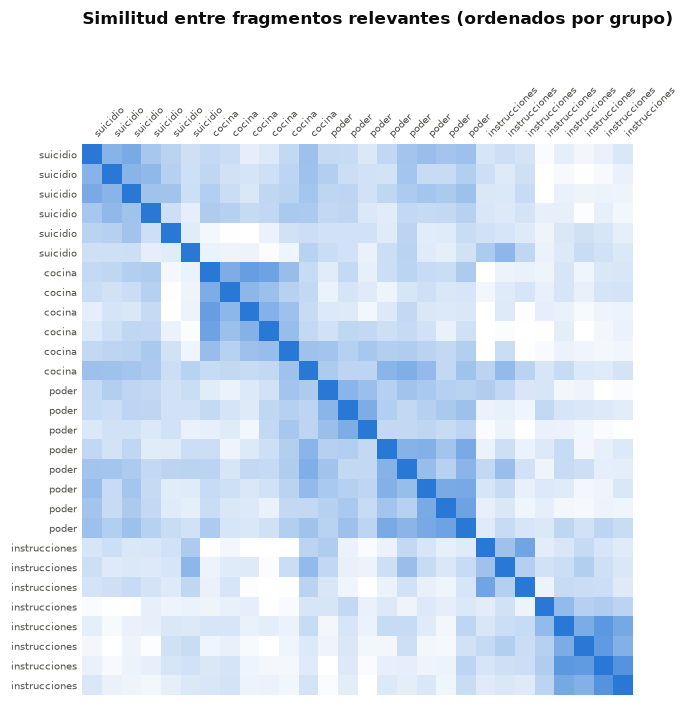

28 fragmentos | coseno promedio dentro del grupo: 0.40 | entre grupos: 0.19


In [19]:
consultas_del_mapa = ["C03", "C04", "C07", "C08"]
nombres_de_los_grupos = {
    "C03": "suicidio", "C04": "cocina", "C07": "poder", "C08": "instrucciones",
}

elegidos = []
grupo_de_cada_uno = []
for id_consulta in consultas_del_mapa:
    totales = juicios[(juicios["id_consulta"] == id_consulta)
                      & (juicios["relevancia"] == 2)]
    for identificador in totales["id_fragmento"]:
        if identificador not in elegidos:
            elegidos.append(identificador)
            grupo_de_cada_uno.append(nombres_de_los_grupos[id_consulta])

lugares = []
for identificador in elegidos:
    lugares.append(lista_de_ids.index(identificador))
embeddings_elegidos = matriz_de_oraciones[lugares]

cantidad = len(lugares)
matriz_de_cosenos = np.zeros((cantidad, cantidad))
for lugar_a in range(cantidad):
    matriz_de_cosenos[lugar_a] = utils.cosenos_contra_todas_las_filas(
        embeddings_elegidos, embeddings_elegidos[lugar_a]
    )

utils.dibujar_mapa_de_calor(
    matriz_de_cosenos, grupo_de_cada_uno, grupo_de_cada_uno,
    "Similitud entre fragmentos relevantes (ordenados por grupo)",
    anotar=False,
)

# El promedio dentro de cada grupo y entre grupos, sin la diagonal.
dentro = []
entre = []
for lugar_a in range(cantidad):
    for lugar_b in range(cantidad):
        if lugar_a == lugar_b:
            continue
        if grupo_de_cada_uno[lugar_a] == grupo_de_cada_uno[lugar_b]:
            dentro.append(matriz_de_cosenos[lugar_a, lugar_b])
        else:
            entre.append(matriz_de_cosenos[lugar_a, lugar_b])
print(f"{cantidad} fragmentos | coseno promedio dentro del grupo: "
      f"{np.mean(dentro):.2f} | entre grupos: {np.mean(entre):.2f}")

> **Para mirar.**
>
> - dentro de un grupo el coseno promedio (0,40) supera al de entre grupos (0,19): se ven cuadrados claros sobre la diagonal.
> - pero esos fragmentos **también** son consecutivos de un mismo cuento (*instrucciones para subir una escalera* aporta cinco): parte del bloque puede deberse a que son del mismo texto y no al tema. La matriz muestra **similitud**, no **pertinencia**.

**PCA** busca los dos ejes sobre los que los 384 números de cada embedding varían más. Fijamos antes **dos componentes** y no probamos otras proyecciones hasta que los grupos se vean separados: eso sería manipular la evidencia. Hay dos preguntas distintas: la calidad de la **representación** (se evalúa con la tarea) y la calidad de la **proyección** (se evalúa comparando distancias antes y después).

Varianza explicada: 16% y 13% (total 29%)


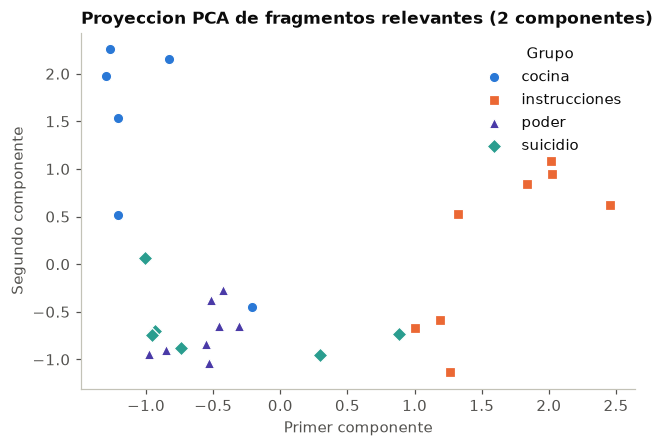

Correlacion entre similitudes originales y del plano: 0.74


In [20]:
proyeccion = PCA(n_components=2, random_state=SEMILLA)
coordenadas = proyeccion.fit_transform(X=embeddings_elegidos)
primer_eje, segundo_eje = proyeccion.explained_variance_ratio_
print(f"Varianza explicada: {primer_eje:.0%} y {segundo_eje:.0%} "
      f"(total {primer_eje + segundo_eje:.0%})")

utils.dibujar_dispersion(
    coordenadas, grupo_de_cada_uno,
    "Proyeccion PCA de fragmentos relevantes (2 componentes)",
    "Primer componente", "Segundo componente",
)

# Calidad de la proyeccion: las similitudes en el plano, contra las originales.
en_2d = np.zeros((cantidad, cantidad))
for lugar_a in range(cantidad):
    en_2d[lugar_a] = utils.cosenos_contra_todas_las_filas(
        coordenadas, coordenadas[lugar_a]
    )
triangulo = np.triu_indices(cantidad, k=1)
correlacion = np.corrcoef(matriz_de_cosenos[triangulo], en_2d[triangulo])
print(f"Correlacion entre similitudes originales y del plano: "
      f"{correlacion[0, 1]:.2f}")

> **Para mirar.**
>
> - los dos ejes explican solo 29 % de la varianza; la correlación entre las similitudes originales y las del plano es 0,74. *Cocina* se separa arriba a la izquierda; *suicidio* y *poder* se superponen.
> - que el gráfico muestre grupos separados depende de la **proyección**, no solo de la representación. La varianza explicada mide variación numérica, no significado. Un gráfico con grupos separados no demuestra que la representación sirva, y uno mezclado no demuestra lo contrario. Para eso está la evaluación con consultas y juicios.

## 7. Decidir cómo usarlos

- **Consultas que describen con otras palabras** (C01, C05): el embedding puso el relevante primero donde TF-IDF lo dejó tercero. Razonable cuando los usuarios no comparten el vocabulario de los textos.
- **Consultas con palabras específicas** (C02, C03, C04): TF-IDF acertó primero, y se puede abrir por qué. Razonable cuando las consultas traen términos que los textos repiten y hay que poder explicar el resultado.
- **Consultas sobre una forma o una estructura** (C08, C10): ninguno alcanza. Haría falta otra señal.
- **Alimentar a un modelo de lenguaje con fragmentos:** un error de ranking es una respuesta sin el fragmento correcto. Con 10 consultas y una diferencia cuyo rango incluye el cero, **no hay evidencia para elegir** entre TF-IDF y el embedding: habría que evaluar con consultas del dominio propio.

Ninguna de estas decisiones dice que un método sea mejor en general, y todas dependen de juicios de una sola persona, casi la mitad discutibles.

### Microlaboratorio 3 — Tu evaluación

**Tarea.** Evaluar los tres métodos con una consulta tuya y tus propios juicios, y decidir cuál usarías.  
**Producto.** `comparar_los_tres_metodos` comprobada, la tabla de tu consulta y tu decisión escrita.  
**Antes de empezar.** Secciones 3 a 5.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `relevancias[...]` | guardar el valor del juicio | dentro del bucle, en la posición `lista_de_ids.index(identificador)` del arreglo, el `valor` |
| (2) `orden` | posiciones ordenadas por puntaje | `utils.ordenar_por_puntaje` aplicada a `funcion(consulta)` |
| (3) `p3` | precisión@3 aceptando parciales | `utils.precision_en_k` con las relevancias ordenadas, `k=3` y `umbral=1` |
| (4) `rr` | rango recíproco aceptando parciales | `utils.rango_reciproco` con las relevancias ordenadas y `umbral=1` |
| Paso 2 `mi_consulta`, `mis_juicios` | tu consulta y al menos 8 juicios (con 2 relevantes totales) | un diccionario `{id_del_fragmento: 0, 1 o 2}`; **juzgá antes de ejecutar la comparación**; buscá candidatos con la celda de abajo |
| Paso 3 `mi_decision` | una o dos oraciones | qué método usarías para tu pregunta y para qué otra pregunta no |

**Comprobación.** para C02 con sus juicios, tu función tiene que dar los mismos valores que la tabla de la sección 4. Después, la celda lista los fragmentos que los métodos pusieron arriba y vos no juzgaste, para una segunda ronda.

> **Ayuda 1.** Los fragmentos sin juicio cuentan como no relevantes: por eso la segunda ronda.  
> **Ayuda 2.** Para (3) y (4) mirá cómo `evaluar_un_metodo` llama a `utils.precision_en_k` y `utils.rango_reciproco`.

In [21]:
# Buscar candidatos por palabra (cambia la palabra).
palabra_de_busqueda = "casa"
candidatos = fragmentos[
    fragmentos["texto"].str.contains(palabra_de_busqueda, case=False)
]
print(f"{len(candidatos)} fragmentos contienen '{palabra_de_busqueda}'")
for fila in candidatos.head(8).itertuples():
    print(f"[{fila.id}] {fila.texto[:110]} ...")

9 fragmentos contienen 'casa'
[una-plaza-en-el-cielo-01] Etelvina y Luis van a casarse. En vísperas de la boda, Luis muere. Etelvina se resigna porque confía en que vo ...
[la-foto-01] Jaime y Paula se casaron. Ya durante la luna de miel fue evidente que Paula se moría. Apenas unos pocos meses  ...
[el-suicida-03] Disparó contra la sien las otras cuatro balas. Inútil. Cerró la Biblia, recogió las cartas y salió del cuarto  ...
[la-melancolia-del-viajero-05] Temen regresar a sus playas, y las desean. No encuentran a la vuelta lo que habían dejado a la partida. Ya no  ...
[romance-viejo-01] Yo salí de mi tierra, hará tantos años, para ir a servir a Dios. Desde que salí de mi tierra me gustan los rec ...
[en-el-frente-04] —Somos de la Y. M. C. A. —dijo el oficial. Y a poco, estos y otros, se reunieron frente a una casa y se sentar ...
[la-cocinera-02] La señora no soportaba tampoco que se le recordara su antiguo régimen para enflaquecer, que ahora descuidaba d ...
[conservacion-de-los-rec

In [22]:
def comparar_los_tres_metodos(consulta: str, juicios_propios: dict) -> tuple:
    """Calcula precision@3 y rango reciproco de los tres metodos.

    Los fragmentos sin juicio cuentan como no relevantes.

    Args:
        consulta: El texto de la consulta.
        juicios_propios: Diccionario {id_del_fragmento: 0, 1 o 2}.

    Returns:
        Una tupla (tabla, sin_juzgar): la tabla de metricas por metodo y
        los ids que algun metodo puso entre los cinco primeros sin juicio.
    """
    relevancias = np.zeros(len(lista_de_ids), dtype=int)
    for identificador, valor in juicios_propios.items():
        pass  # COMPLETAR (1)

    filas = []
    sin_juzgar = set()
    for nombre, funcion in METODOS.items():
        orden = []  # COMPLETAR (2)
        ordenadas = relevancias[orden]
        p3 = 0.0  # COMPLETAR (3)
        rr = 0.0  # COMPLETAR (4)
        filas.append({"metodo": nombre, "P@3 (>=1)": p3, "RR (>=1)": rr})
        for lugar in orden[:5]:
            if lista_de_ids[lugar] not in juicios_propios:
                sin_juzgar.add(lista_de_ids[lugar])
    return pd.DataFrame(filas).set_index("metodo"), sorted(sin_juzgar)


# Comprobacion: con los juicios de C02, debe dar la tabla de la seccion 4.
juicios_c02 = {}
for fila in juicios[juicios["id_consulta"] == "C02"].itertuples():
    juicios_c02[fila.id_fragmento] = int(fila.relevancia)
texto_c02 = consultas.loc[consultas["id"] == "C02", "consulta"].iloc[0]
tabla_c02, _ = comparar_los_tres_metodos(texto_c02, juicios_c02)

iguales = True
for nombre in METODOS:
    esperada = resultados_por_metodo[nombre].loc["C02"]
    if abs(tabla_c02.loc[nombre, "P@3 (>=1)"] - esperada["P@3 (>=1)"]) > 1e-9:
        iguales = False
    if abs(tabla_c02.loc[nombre, "RR (>=1)"] - esperada["RR (>=1)"]) > 1e-9:
        iguales = False
utils.comprobar(iguales, "revisa (1) a (4): C02 debe dar lo de la seccion 4")

# PASO 2: tu consulta y tus juicios (al menos 8, con 2 relevantes totales).
mi_consulta = "Alguien espera algo que no llega"
mis_juicios = {
    "una-plaza-en-el-cielo-01": 2,
    "una-plaza-en-el-cielo-03": 1,
}
totales = 0
for valor in mis_juicios.values():
    if valor == 2:
        totales += 1
if totales == 0:
    print("Agrega al menos un fragmento con juicio 2 para poder evaluar.")
else:
    mi_tabla, ids_sin_juzgar = comparar_los_tres_metodos(
        mi_consulta, mis_juicios
    )
    display(mi_tabla.round(2))
    print("Arriba en algun metodo y sin juicio (juzgalos y volve a correr):")
    print(ids_sin_juzgar)

# PASO 3: tu decision entre las comillas.
mi_decision = ""
utils.comprobar(
    len(mi_decision.split()) >= 8,
    "escribi al menos una oracion completa en mi_decision",
)

Todavia falta. Pista: revisa (1) a (4): C02 debe dar lo de la seccion 4


,P@3 (>=1),RR (>=1)
metodo,,
TF-IDF,0.0,0.0
promedio de vectores,0.0,0.0
embedding de oracion,0.0,0.0


Arriba en algun metodo y sin juicio (juzgalos y volve a correr):
[]
Todavia falta. Pista: escribi al menos una oracion completa en mi_decision


**Qué cuenta como evidencia en tu decisión:** juicios fijados antes de ver resultados, casos favorables **y** contraejemplos con su hipótesis, y los límites (otro evaluador, otras consultas, otro modelo). **No cuenta:** números altos, un gráfico con grupos separados o un único ejemplo que funcione.

## Qué te llevás

- «Mejor» es un juicio: se fija el criterio antes, se mira por qué falla cada método y se mide con límites explícitos.
- Con 10 consultas y juicios de una persona, la diferencia entre TF-IDF y el embedding **no alcanza para decidir**; ningún método resuelve las consultas de forma o estructura.
- Un gráfico no es una evaluación: la calidad de la proyección es distinta de la calidad de la representación.

**Sigue:** las próximas unidades (redes neuronales y Transformers) cambian cómo se construye el vector de cada texto; la evaluación sigue siendo la misma.